## MEET THE DATA

In [49]:
import pandas as pd

df = pd.read_csv('/content/abuja_apartments_400.csv')

In [50]:
df.head()

,apartment_id,bedrooms,size_sqm,distance_to_city_km,has_generator,has_security,rent_per_year,rent_category
0,APT001,1,25,8.5,No,No,840000,Affordable
1,APT002,3,86,28.3,Yes,No,1950000,Affordable
2,APT003,2,65,7.9,Yes,Yes,2160000,Expensive
3,APT004,2,68,22.1,No,No,1350000,Affordable
4,APT005,2,56,6.4,No,Yes,1660000,Affordable


In [51]:
# 1. Check for missing values
print("Missing values:")
print(df.isnull().sum())

# 2. Check for duplicate rows
print("\nDuplicate rows:")
print(df.duplicated().sum())

# 3. Count apartments in each rent category
print("\nRent category counts:")
print(df['rent_category'].value_counts())

# 4. Summary statistics for numerical columns
print("\nSummary statistics:")
df.describe()

Missing values:
apartment_id           0
bedrooms               0
size_sqm               0
distance_to_city_km    0
has_generator          0
has_security           0
rent_per_year          0
rent_category          0
dtype: int64

Duplicate rows:
0

Rent category counts:
rent_category
Affordable    226
Expensive     174
Name: count, dtype: int64

Summary statistics:


,bedrooms,size_sqm,distance_to_city_km,rent_per_year
count,400.000000,400.000000,400.000000,4.000000e+02
mean,2.305000,71.272500,15.396250,1.901675e+06
std,0.958787,24.514805,8.405724,6.811246e+05
min,1.000000,25.000000,1.200000,6.000000e+05
25%,2.000000,53.000000,7.875000,1.370000e+06
50%,2.000000,70.500000,15.500000,1.865000e+06
75%,3.000000,89.000000,22.450000,2.405000e+06
max,4.000000,135.000000,29.800000,3.510000e+06


In [52]:
import matplotlib.pyplot as plt

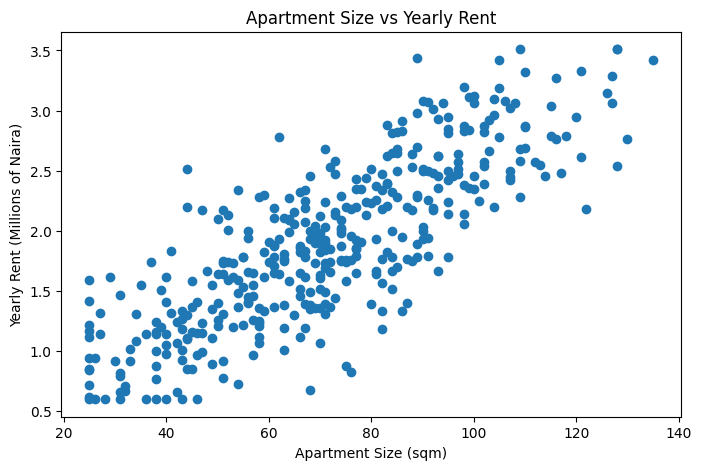

In [53]:
plt.figure(figsize=(8, 5))

plt.scatter(df['size_sqm'], df['rent_per_year'] / 1000000)

plt.title('Apartment Size vs Yearly Rent')
plt.xlabel('Apartment Size (sqm)')
plt.ylabel('Yearly Rent (Millions of Naira)')

plt.show()

The scatter plot shows a positive relationship between apartment size and yearly rent. Generally, larger apartments have higher rents, but the dots do not fall exactly on a straight line because other factors also influence rent.

## Part 2: PREPARE THE DATA

#Task 2.1: Choose features and target
Target (y): rent_per_year

Features (X): bedrooms, size_sqm, distance_to_city_km, has_generator, and has_security.

Column to leave out: apartment_id, because it is only an identifier or name tag.

We won't use rent_per_year to predict rent_category because rent_category is determined from the yearly rent. Using rent_per_year would give the model the answer it is supposed to predict


In [54]:
df_ml = df.copy()

df_ml['has_generator_num'] = df_ml['has_generator'].map({'Yes': 1, 'No': 0})

df_ml['has_security_num'] = df_ml['has_security'].map({'Yes': 1, 'No': 0})

In [55]:
features = [
    'bedrooms',
    'size_sqm',
    'distance_to_city_km',
    'has_generator_num',
    'has_security_num'
]

In [56]:
df_ml[['has_generator', 'has_generator_num', 'has_security', 'has_security_num']].head()

,has_generator,has_generator_num,has_security,has_security_num
0,No,0,No,0
1,Yes,1,No,0
2,Yes,1,Yes,1
3,No,0,No,0
4,No,0,Yes,1


In [57]:
from sklearn.model_selection import train_test_split

In [58]:
train_df, test_df = train_test_split(
    df_ml,
    test_size=0.2,
    random_state=42
)

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

Training rows: 320
Testing rows: 80


1. Why did we change Yes/No into 1/0?

We changed Yes to 1 and No to 0 because machine learning models work with numerical data, making it easier for the model to process the information.

2. Why did we keep 20% of the data for testing?

We kept 20% of the data for testing so we can evaluate how well the model predicts results using apartments it has not seen during training.

## PART 3: REGRESSION, PREDICTING THE RENT

In [59]:
X_train = train_df[['size_sqm']]
y_train = train_df['rent_per_year']

X_test = test_df[['size_sqm']]
y_test = test_df['rent_per_year']

In [60]:
from sklearn.linear_model import LinearRegression

In [61]:
model_simple = LinearRegression()
model_simple.fit(X_train, y_train)

LinearRegression()

In [62]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

In [63]:
y_pred_simple = model_simple.predict(X_test)

mae_simple = mean_absolute_error(y_test, y_pred_simple)
r2_simple = r2_score(y_test, y_pred_simple)

print("Mean Absolute Error:", mae_simple)
print("R-squared:", r2_simple)

Mean Absolute Error: 307704.1278625683
R-squared: 0.618127159919531


The model has an MAE of approximately ₦307,704, meaning its predictions differ from actual rent by about this amount on average.

Its R-squared value of 0.6181 shows that apartment size explains about 61.81% of the variation in yearly rent.

Before training the model with all five features, I think the MAE will be bigger because adding more features may introduce more complexity into the model.

In [64]:
X_train_multi = train_df[features]
X_test_multi = test_df[features]

y_train_multi = train_df['rent_per_year']
y_test_multi = test_df['rent_per_year']

In [65]:
model_multi = LinearRegression()

model_multi.fit(X_train_multi, y_train_multi)

LinearRegression()

In [66]:
y_pred_multi = model_multi.predict(X_test_multi)

mae_multi = mean_absolute_error(y_test_multi, y_pred_multi)
r2_multi = r2_score(y_test_multi, y_pred_multi)

print("Mean Absolute Error:", mae_multi)
print("R-squared:", r2_multi)

Mean Absolute Error: 171685.31661888
R-squared: 0.8972706081668563


## Comparing both models
Evaluation	Simple model (1 feature):
MAE ₦307,704.13
R²	0.6181

Multiple model (5 features)
MAE	₦171,685.32
R²	0.8973


In [67]:
coefficients = pd.DataFrame({
    'Feature': features,
    'Slope': model_multi.coef_
})

coefficients

,Feature,Slope
0,bedrooms,381717.865276
1,size_sqm,10704.623501
2,distance_to_city_km,-20274.436835
3,has_generator_num,318491.279697
4,has_security_num,240705.117081


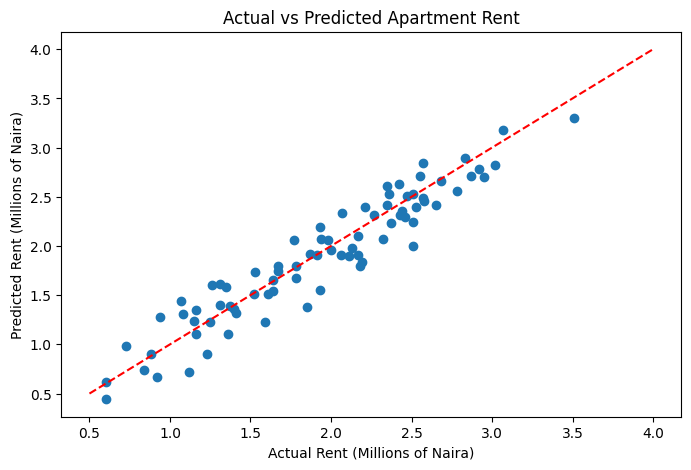

In [68]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test_multi / 1000000, y_pred_multi / 1000000)

plt.plot(
    [0.5, 4],
    [0.5, 4],
    color='red',
    linestyle='--'
)

plt.title('Actual vs Predicted Apartment Rent')
plt.xlabel('Actual Rent (Millions of Naira)')
plt.ylabel('Predicted Rent (Millions of Naira)')

plt.show()

Most of the points are close to the red dashed line, showing that the model's predictions are generally close to the actual rents.

Some points are above or below the line, indicating that the model sometimes overestimates or underestimates rent.

In [69]:
new_apartment = pd.DataFrame({
    'bedrooms': [3],
    'size_sqm': [90],
    'distance_to_city_km': [10],
    'has_generator_num': [1],
    'has_security_num': [1]
})

predicted_rent = model_multi.predict(new_apartment)

print("Predicted Yearly Rent: ₦{:,.2f}".format(predicted_rent[0]))

Predicted Yearly Rent: ₦2,730,362.44


The model predicted a yearly rent of ₦2,730,362.44 for the new apartment based on its five features.

##PART 4: CLASSIFICATION: EXPENSIVE OR AFFORDABLE

In [70]:
from sklearn.tree import DecisionTreeClassifier

In [71]:
model_tree = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

X_train_class = train_df[features]
X_test_class = test_df[features]

y_train_class = train_df['rent_category']
y_test_class = test_df['rent_category']

model_tree.fit(X_train_class, y_train_class)

DecisionTreeClassifier(max_depth=3, random_state=42)

In [72]:
from sklearn.metrics import accuracy_score

In [73]:
y_pred_class = model_tree.predict(X_test_class)

accuracy = accuracy_score(y_test_class, y_pred_class)

print("Accuracy:", accuracy * 100, "%")

Accuracy: 77.5 %


The Decision Tree model achieved an accuracy of 77.5%. This means it correctly classified 62 out of the 80 test apartments as either Expensive or Affordable.

In [74]:
from sklearn.tree import plot_tree

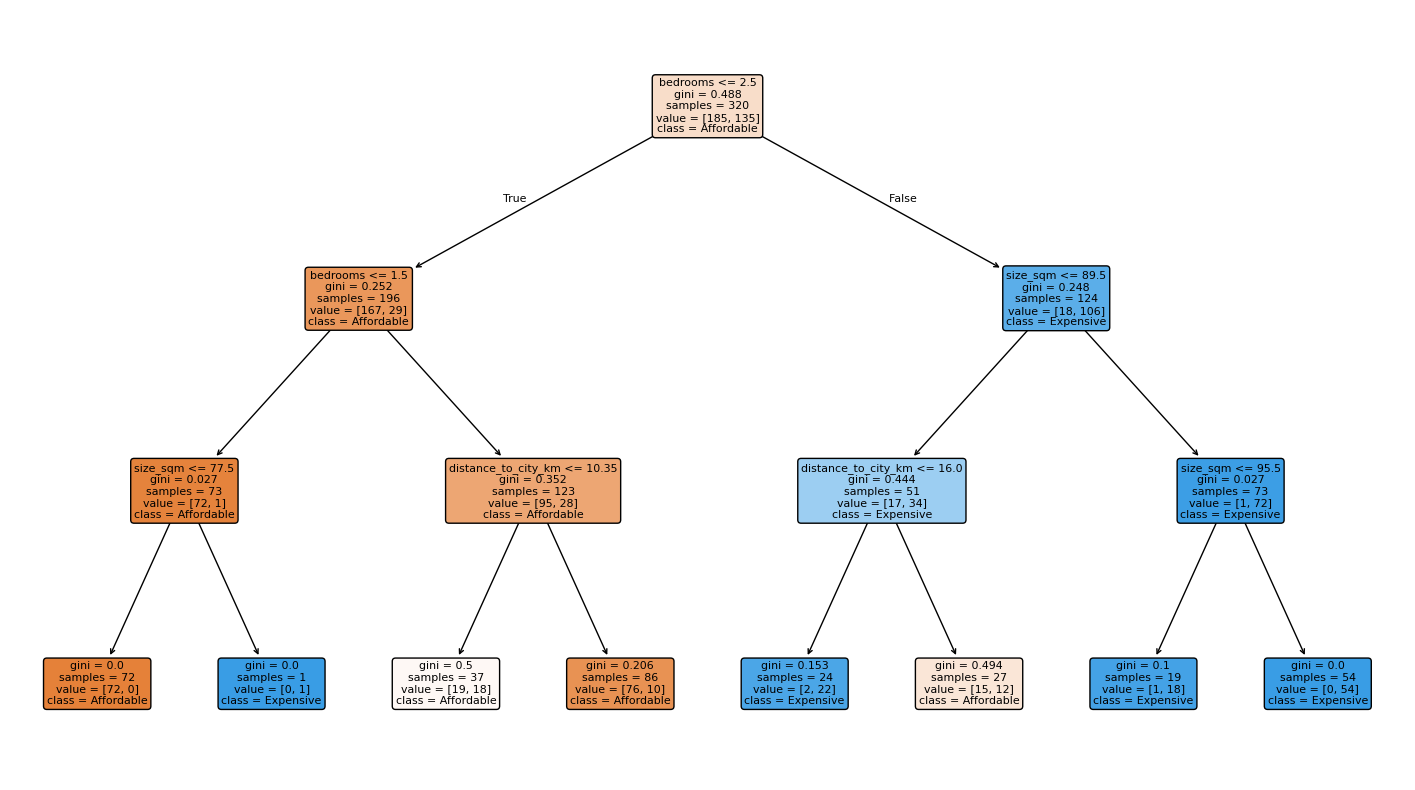

In [75]:
plt.figure(figsize=(18, 10))

plot_tree(
    model_tree,
    feature_names=features,
    class_names=model_tree.classes_,
    filled=True,
    rounded=True
)

plt.show()

The first question the decision tree asks is bedroom <= 2.5 which is whether the number of bedrooms is less than or equal to 2.5. The features it uses are bedrooms, size_sqm, and distance_to_city_km.

In [76]:
new_apartment = pd.DataFrame(
    [[3, 90, 10, 1, 1]],
    columns=features
)

prediction = model_tree.predict(new_apartment)

print("Predicted Rent Category:", prediction[0])

Predicted Rent Category: Expensive


The Decision Tree classified the new apartment as Expensive. This agrees with the Linear Regression prediction of ₦2,730,362.44 per year, which is above the ₦2,000,000 threshold for Expensive apartments.

## PART 5: OVERFITTING

To guess first

I think training accuracy will increase as the tree depth increases. Testing accuracy may decrease if the model overfits the training data.

In [77]:
import numpy as np

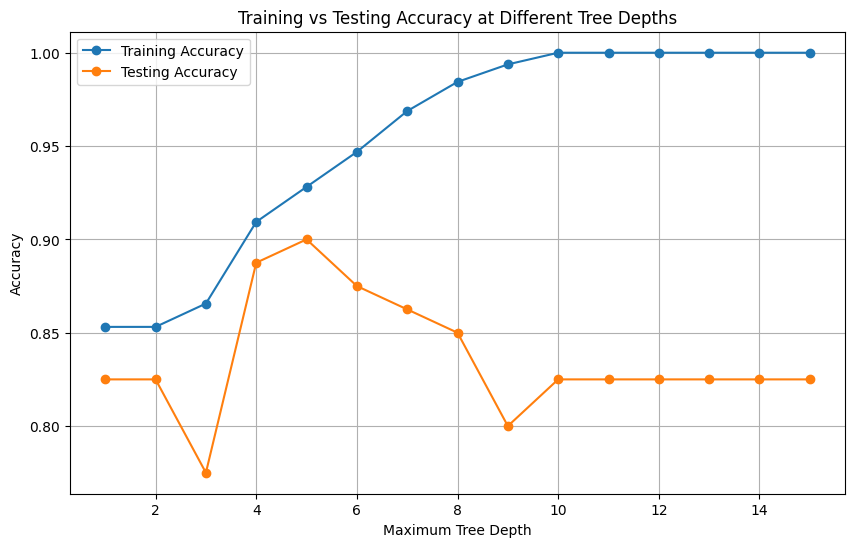

Best Depth: 5


In [78]:
depths = range(1, 16)

train_accuracies = []
test_accuracies = []

for depth in depths:
    tree = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    tree.fit(X_train_class, y_train_class)

    train_pred = tree.predict(X_train_class)
    test_pred = tree.predict(X_test_class)

    train_accuracies.append(
        accuracy_score(y_train_class, train_pred)
    )

    test_accuracies.append(
        accuracy_score(y_test_class, test_pred)
    )

plt.figure(figsize=(10, 6))

plt.plot(depths, train_accuracies, marker='o', label='Training Accuracy')
plt.plot(depths, test_accuracies, marker='o', label='Testing Accuracy')

plt.xlabel('Maximum Tree Depth')
plt.ylabel('Accuracy')
plt.title('Training vs Testing Accuracy at Different Tree Depths')
plt.legend()
plt.grid(True)

plt.show()

best_depth = depths[np.argmax(test_accuracies)]
print("Best Depth:", best_depth)

In [79]:
tree_full = DecisionTreeClassifier(random_state=42)

tree_full.fit(X_train_class, y_train_class)

train_pred_full = tree_full.predict(X_train_class)
test_pred_full = tree_full.predict(X_test_class)

print("Training Accuracy:", accuracy_score(y_train_class, train_pred_full) * 100, "%")
print("Testing Accuracy:", accuracy_score(y_test_class, test_pred_full) * 100, "%")

Training Accuracy: 100.0 %
Testing Accuracy: 82.5 %


1. The unrestricted Decision Tree achieved 100% training accuracy and 82.5% testing accuracy. This suggests overfitting because the model performed perfectly on the training data but less accurately on unseen data.

2. Overfitting occurs when a machine learning model learns the training data too closely, including details that may not apply to new data. As a result, it performs very well on training data but may perform less accurately on unseen testing data.

3. would choose a maximum depth of 5 because it achieved the highest testing accuracy among the 15 depths tested. I would not automatically choose the deepest tree because a deeper tree may overfit the training data and perform poorly on unseen data.

## PART 6: REFLECTION

1. The multiple regression model performed better, with a lower MAE and higher R² than the simple model.

2. Apartments with generators are predicted to have about ₦318,491 higher yearly rent, keeping other features constant.

3. Testing on unseen apartments helps us evaluate how well the model predicts data it has not encountered before.

4. The dataset contains only 400 made-up apartments, so it may not accurately represent real rental prices in Abuja.

5. (a) An algorithm is the learning method; a model is what is produced after training.

(b)
- Create: Set up the algorithm.
- Fit: Train the model.
- Predict: Make predictions using the trained model.